In [21]:
from langgraph.graph import StateGraph, START, END
from langchain_groq import ChatGroq
from typing import TypedDict, Annotated, Literal
from dotenv import load_dotenv
from pydantic import BaseModel, Field
from langchain_core.messages import SystemMessage, HumanMessage, AIMessage
import operator

from langgraph.checkpoint.memory import MemorySaver

In [5]:
load_dotenv()

True

In [6]:
model = ChatGroq(model="openai/gpt-oss-20b")

In [4]:
from langgraph.graph.message import add_messages
from langchain_core.messages import BaseMessage

class ChatState(TypedDict):
    messages : Annotated[list[BaseMessage], add_messages]

In [7]:
def chat_node(state : ChatState):

    # Take user query from state
    messages = state['messages']

    # send to llm
    response = model.invoke(messages)

    # response store state
    return {'messages' : [response]}

In [1]:
checkpointer = MemorySaver()

graph = StateGraph(ChatState)

graph.add_node('chat_node', chat_node)
graph.add_edge(START, 'chat_node')
graph.add_edge('chat_node', END)

chatbot = graph.compile(checkpointer=checkpointer)

NameError: name 'MemorySaver' is not defined

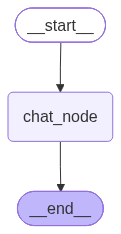

In [24]:
graph.compile()

In [17]:
intial_state = {
    'messages' : [HumanMessage(content = 'what is the capital of India')]
}

response = chatbot.invoke(intial_state)

In [25]:
thread_id = '1'

while True:
    user_message = input("Type here : ")

    print('User : ',user_message)

    if user_message.strip().lower() in ['exit', 'quit', 'bye','end'] :
        break

    config = {'configurable' : {'thread_id' : thread_id}}
    response = chatbot.invoke({'messages':[HumanMessage(content=user_message)]}, config = config)

    print('AI: ', response['messages'][-1].content)

User :  Hi my name is Rishi
AI:  Hello Rishi! 👋 How can I help you today?
User :  tell me my name
AI:  Your name is Rishi.
User :  do you know 9/11 attack
AI:  Yes, I can provide information about the September 11, 2001 attacks (often referred to as 9/11). Here’s a concise overview:

| Topic | Key Details |
|-------|-------------|
| **Date & Time** | September 11, 2001 (morning U.S. Eastern Time) |
| **Perpetrators** | 19 terrorists from the Islamist extremist group **Al‑Qaida** |
| **Targets** | - **World Trade Center (WTC)** in New York City (North & South towers) <br>- **Pentagon** in Arlington, Virginia <br>- **United Airlines Flight 93** (crashed in Pennsylvania; passengers attempted to regain control) |
| **Method** | Hijacked commercial airliners and used them as weapons (controlled crashes). |
| **Casualties** | • **~2,977** people died (including 246 passengers on the planes, 2,606 at the WTC, 125 at the Pentagon, and 40 in Pennsylvania). <br>• **~6,000** injured. |
| **Immedi

In [26]:
chatbot.get_state(config = config)

StateSnapshot(values={'messages': [HumanMessage(content='Hi my name is Rishi', additional_kwargs={}, response_metadata={}, id='4fc5ad2a-79c6-4514-af0f-b016ac930042'), AIMessage(content='Hello Rishi! 👋 How can I help you today?', additional_kwargs={'reasoning_content': 'The user says "Hi my name is Rishi". We need to respond. It\'s a greeting, so we can greet back. Also we can ask if they need help. The user hasn\'t asked anything. So we should respond politely.'}, response_metadata={'token_usage': {'completion_tokens': 70, 'prompt_tokens': 77, 'total_tokens': 147, 'completion_time': 0.072550439, 'completion_tokens_details': {'reasoning_tokens': 48}, 'prompt_time': 0.004373368, 'prompt_tokens_details': None, 'queue_time': 0.340673357, 'total_time': 0.076923807}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_851252edc2', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a10227-03a9-76a2-956b-b5bd2e464366-0', t